Датасет CIFAR-10 состоит из цветных картинок 32 × 32, разделённых на 10 классов:

__airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck__.

# Импорты

In [3]:
import tensorflow as tf
import tensorflow.keras as keras
import tensorflow.keras.models as M
import tensorflow.keras.layers as L
import tensorflow.keras.backend as K
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
print(tf.__version__)
print(keras.__version__)

2.20.0
3.13.2


# Загружаем данные

In [4]:
from tensorflow.keras.datasets import cifar10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 13s 0us/step


In [5]:
print("Трейн:", x_train.shape, y_train.shape)
print("Тест:", x_test.shape, y_test.shape)

Трейн: (50000, 32, 32, 3) (50000, 1)
Тест: (10000, 32, 32, 3) (10000, 1)


In [6]:
NUM_CLASSES = 10
cifar10_classes = ["airplane", "automobile", "bird", "cat", "deer",
                   "dog", "frog", "horse", "ship", "truck"]

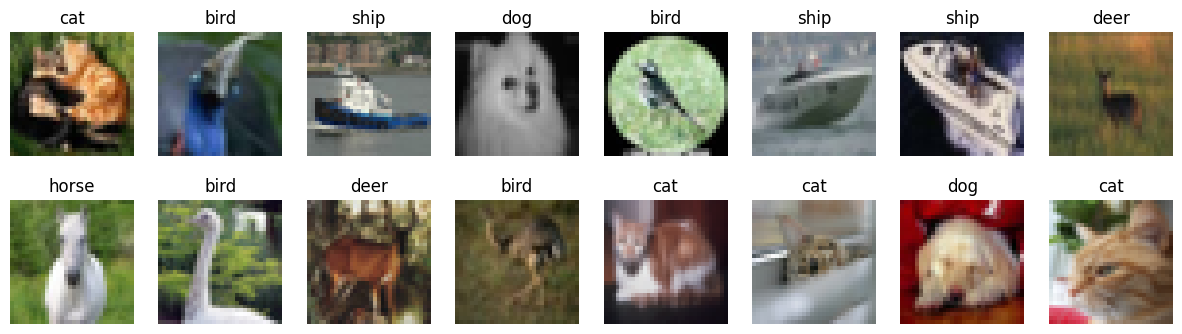

In [7]:
# посмотрим на примеры картинок
cols = 8
rows = 2
fig = plt.figure(figsize=(2 * cols - 1, 2.5 * rows - 1))
for i in range(cols):
    for j in range(rows):
        random_index = np.random.randint(0, len(y_train))
        ax = fig.add_subplot(rows, cols, i * rows + j + 1)
        ax.grid('off')
        ax.axis('off')
        ax.imshow(x_train[random_index, :])
        ax.set_title(cifar10_classes[y_train[random_index, 0]])
plt.show()

# Готовим данные

In [8]:
# нормализуем входы
x_train2 = x_train.astype('float32') / 255 - 0.5
x_test2 = x_test.astype('float32') / 255 - 0.5

# конвертируем метки в np.array (?, NUM_CLASSES)
y_train2 = keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test2 = keras.utils.to_categorical(y_test, NUM_CLASSES)

## Задаём *дефолтную* архитектуру сети

In [9]:
# слои, которые нам пригодятся
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization

In [10]:
def make_default_model():
    model = Sequential()

# 4 свёрточных слоя
    model.add(Conv2D(16, (3, 3), padding='same', activation='relu', input_shape=(32, 32, 3)))
    model.add(Conv2D(32, (3, 3), padding='same', activation='relu'))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Dropout(0.25))

    model.add(Conv2D(32, (3, 3), padding='same', activation='relu'))
    model.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Dropout(0.25))

    # Полносвязная часть
    model.add(Flatten())
    model.add(Dense(256, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(10, activation='softmax'))

    return model

In [11]:
K.clear_session()
model = make_default_model()
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,084,234 (4.14 MB)

 Trainable params: 1,084,234 (4.14 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Создаём генератор с аугментацией для обучения
train_datagen = ImageDataGenerator(
    rotation_range=15,           # случайный поворот в пределах 15 градусов
    width_shift_range=0.1,       # горизонтальный сдвиг
    height_shift_range=0.1,      # вертикальный сдвиг
    horizontal_flip=True,        # горизонтальное отражение
    zoom_range=0.1,              # случайное масштабирование
    fill_mode='nearest'          # способ заполнения пикселей после трансформации
)

# Генератор без аугментации для валидации
val_datagen = ImageDataGenerator()

# Применяем генераторы к данным
train_generator = train_datagen.flow(
    x_train2, y_train2,
    batch_size=64,
    shuffle=True
)

val_generator = val_datagen.flow(
    x_test2, y_test2,
    batch_size=64,
    shuffle=False
)

# Тренируем модель

In [13]:
import math
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [14]:
def train_model(make_model_func=make_default_model, optimizer="adam", epochs=10):
    BATCH_SIZE = 64

    K.clear_session()
    model = make_model_func()

    model.compile(
        loss='categorical_crossentropy',
        optimizer=optimizer,
        metrics=['accuracy']
    )

    # Аугментация для тренировочных данных
    train_datagen = ImageDataGenerator(
        rotation_range=15,
        width_shift_range=0.1,
        height_shift_range=0.1,
        horizontal_flip=True,
        zoom_range=0.1,
        fill_mode='nearest'
    )

    # Для валидации только нормализация
    val_datagen = ImageDataGenerator()

    train_generator = train_datagen.flow(
        x_train2, y_train2,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    val_generator = val_datagen.flow(
        x_test2, y_test2,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    # расчёт steps: общее количество образцов / размер батча
    import math
    steps_per_epoch = math.ceil(len(x_train2) / BATCH_SIZE)
    validation_steps = math.ceil(len(x_test2) / BATCH_SIZE)

    history = model.fit(
        train_generator,
        steps_per_epoch=steps_per_epoch,
        epochs=epochs,
        validation_data=val_generator,
        validation_steps=validation_steps,
        verbose=1
    )

    return model, history

In [15]:
model_aug, history_aug = train_model(epochs=20)


Epoch 1/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 45s 49ms/step - accuracy: 0.3935 - loss: 1.6575 - val_accuracy: 0.5328 - val_loss: 1.2894
Epoch 2/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 35s 45ms/step - accuracy: 0.5236 - loss: 1.3222 - val_accuracy: 0.6228 - val_loss: 1.0529
Epoch 3/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 34s 43ms/step - accuracy: 0.5748 - loss: 1.1854 - val_accuracy: 0.6475 - val_loss: 1.0016
Epoch 4/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 32s 41ms/step - accuracy: 0.6103 - loss: 1.0973 - val_accuracy: 0.6451 - val_loss: 1.0163
Epoch 5/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 42s 42ms/step - accuracy: 0.6352 - loss: 1.0353 - val_accuracy: 0.7048 - val_loss: 0.8459
Epoch 6/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 41s 42ms/step - accuracy: 0.6467 - loss: 1.0041 - val_accuracy: 0.7162 - val_loss: 0.8054
Epoch 7/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 32s 41ms/step - accuracy: 0.6624 - loss: 0.9690 - val_accuracy: 0.6963 - val_loss: 0.8692
Epoch 8/20
782/782 ━━━━━━━━━━━━━━━━━━━━ 32s 40ms/step - accuracy: 0.6700 - loss: 0.9384 - 

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
              precision    recall  f1-score   support

    airplane       0.80      0.80      0.80      1000
  automobile       0.88      0.92      0.90      1000
        bird       0.82      0.47      0.60      1000
         cat       0.65      0.54      0.59      1000
        deer       0.74      0.71      0.73      1000
         dog       0.78      0.60      0.68      1000
        frog       0.56      0.94      0.70      1000
       horse       0.82      0.83      0.82      1000
        ship       0.90      0.85      0.87      1000
       truck       0.79      0.92      0.85      1000

    accuracy                           0.76     10000
   macro avg       0.77      0.76      0.75     10000
weighted avg       0.77      0.76      0.75     10000


Всего ошибок: 2422 из 10000


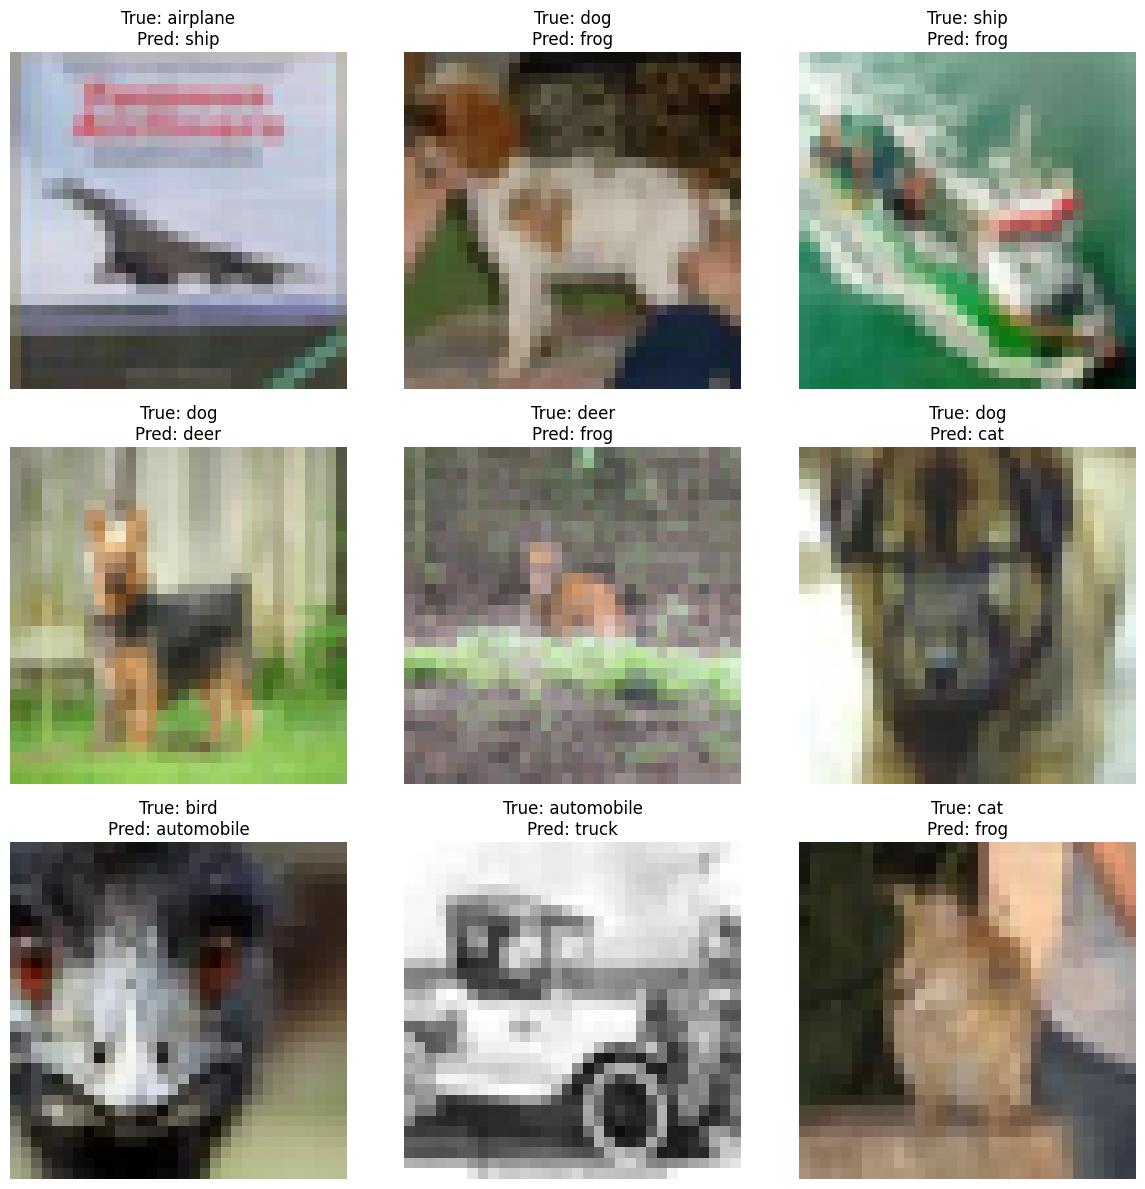

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

# Предсказания
y_pred = model_aug.predict(x_test2)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test2, axis=1)

# Отчёт по классам

print(classification_report(y_true, y_pred_classes, target_names=cifar10_classes))

# Покажем 9 ошибок
errors = np.where(y_pred_classes != y_true)[0]
print(f"Всего ошибок: {len(errors)} из 10000")

plt.figure(figsize=(12, 12))
for i in range(9):
    idx = errors[i]
    plt.subplot(3, 3, i+1)
    plt.imshow(x_test[idx])
    plt.title(f'True: {cifar10_classes[y_true[idx]]}\nPred: {cifar10_classes[y_pred_classes[idx]]}')
    plt.axis('off')
plt.tight_layout()
plt.show()

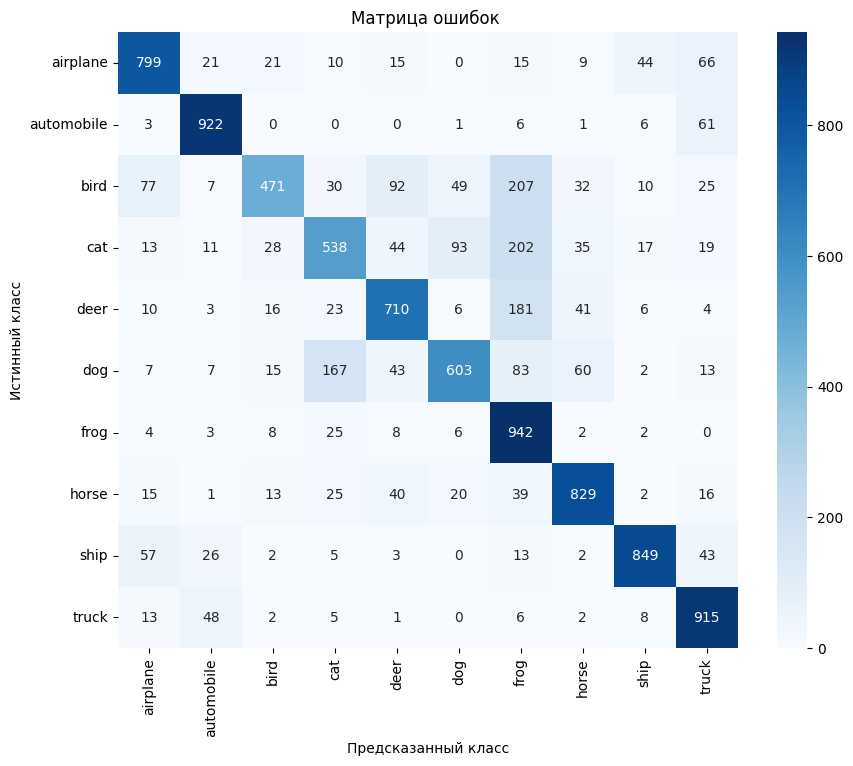

In [17]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=cifar10_classes,
            yticklabels=cifar10_classes)
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.title('Матрица ошибок ')
plt.show()

**Модель достигла точности 75% на валидационной выборке.**

**Лучше всего распознаются:** автомобили , грузовики, корабли.

**Хуже всего распознаются:** птицы (49%), кошки (52%), собаки (57%).

**Основные ошибки:** птицу распознали как лягушку 207 раз, оленя как лягушку 181 раз, кошку как лягушку 202 раза, собаку как кошку 167 раза.

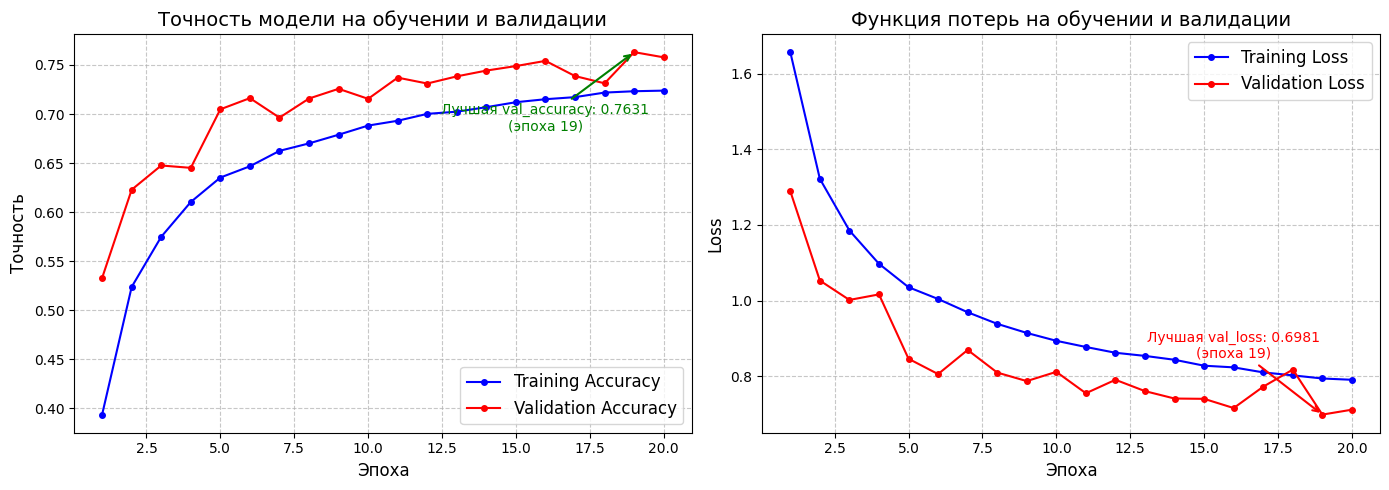

In [18]:
# графики обучения
# Извлечение данных из history
train_acc = history_aug.history['accuracy']
val_acc = history_aug.history['val_accuracy']
train_loss = history_aug.history['loss']
val_loss = history_aug.history['val_loss']
epochs_range = range(1, len(train_acc) + 1)

# Находим лучшие результаты
best_val_acc = max(val_acc)
best_val_acc_epoch = val_acc.index(best_val_acc) + 1
best_val_loss = min(val_loss)
best_val_loss_epoch = val_loss.index(best_val_loss) + 1

plt.figure(figsize=(14, 5))

# График 1: Точность
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_acc, 'b-o', label='Training Accuracy', markersize=4, linewidth=1.5)
plt.plot(epochs_range, val_acc, 'r-o', label='Validation Accuracy', markersize=4, linewidth=1.5)
plt.title('Точность модели на обучении и валидации', fontsize=14)
plt.xlabel('Эпоха', fontsize=12)
plt.ylabel('Точность', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
# Аннотация с лучшей точностью
plt.annotate(f'Лучшая val_accuracy: {best_val_acc:.4f}\n(эпоха {best_val_acc_epoch})',
             xy=(best_val_acc_epoch, best_val_acc),
             xytext=(best_val_acc_epoch - 3, best_val_acc - 0.08),
             arrowprops=dict(arrowstyle='->', color='green', lw=1.5),
             fontsize=10, color='green', ha='center')

# График 2: Потери
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_loss, 'b-o', label='Training Loss', markersize=4, linewidth=1.5)
plt.plot(epochs_range, val_loss, 'r-o', label='Validation Loss', markersize=4, linewidth=1.5)
plt.title('Функция потерь на обучении и валидации', fontsize=14)
plt.xlabel('Эпоха', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
# Аннотация с лучшими потерями
plt.annotate(f'Лучшая val_loss: {best_val_loss:.4f}\n(эпоха {best_val_loss_epoch})',
             xy=(best_val_loss_epoch, best_val_loss),
             xytext=(best_val_loss_epoch - 3, best_val_loss + 0.15),
             arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
             fontsize=10, color='red', ha='center')

plt.tight_layout()
plt.show()


In [20]:
# статистики

print(f"Начальная точность на обучении: {train_acc[0]:.4f}")
print(f"Конечная точность на обучении: {train_acc[-1]:.4f}")
print(f"Начальная точность на валидации: {val_acc[0]:.4f}")
print(f"Конечная точность на валидации: {val_acc[-1]:.4f}")
print(f"Лучшая точность на валидации: {best_val_acc:.4f} (эпоха {best_val_acc_epoch})")
print(f"Лучший loss на валидации: {best_val_loss:.4f} (эпоха {best_val_loss_epoch})")
print(f"Разрыв между train и val accuracy: {abs(train_acc[-1] - val_acc[-1]):.4f}")

# анализ переобучения
if val_acc[-1] > train_acc[-1] * 0.95:
    print("сильного переобучения нет.")
elif val_acc[-1] > train_acc[-1] * 0.9:
    print("небольшое переобучение")
else:
    print("переобучение сильное")

Начальная точность на обучении: 0.3935
Конечная точность на обучении: 0.7239
Начальная точность на валидации: 0.5328
Конечная точность на валидации: 0.7578
Лучшая точность на валидации: 0.7631 (эпоха 19)
Лучший loss на валидации: 0.6981 (эпоха 19)
Разрыв между train и val accuracy: 0.0339
сильного переобучения нет.
